# Evaluating simple forecasting baselines

> **Historical v1 analysis.** The modelling target in this workflow ends in September 2025; newer supplemental observations remain separate here. For the current 519-game forecast, see [Notebook 20](20_fixed_cohort_2027_forecast.ipynb). [Notebook 17](17_fixed_sources_integration.ipynb) begins the separate v2 workflow.

![05 / Baseline Evaluation — Historical forecast comparisons and error interpretation](assets/pixel_theme/05_baseline_evaluation.svg)

The last-value baseline has lower average monthly error than seasonal naive across all five labels in the four historical cutoffs tested. The comparison changes across individual cutoffs and the average of a distant 12-month target window, making the metric and forecast task important parts of the result.

This stage establishes reference errors for later models using recorded category activity, with the incomplete app histories and retrospective metadata assumptions carried forward.


## Scope and evaluation design

The target is the sum of observed eligible category activity in database/steam.sqlite. App-level gaps stay unknown and contribute to the source's incomplete recorded totals, while the category series must have a complete monthly calendar and a nonmissing recorded total in every month for this benchmark run.

Four fixed origins use June 2020, June 2021, June 2022, and June 2023. Each method forecasts the next **27 months without updating from later actuals**, matching the lead length from the v1 September 2025 cutoff to December 2027.

Leads **16–27** receive a separate score because January–December 2027 occupies those leads from September 2025. The historical June-origin target windows run October–September, so this comparison matches the lead distance and 12-month length rather than the calendar-year season alignment.

The folds overlap and all origins occur in June, which limits the independence and calendar variety of the evidence. Earlier exploration already inspected the historical data, and the labels and eligibility use a later snapshot, so this is retrospective development evaluation rather than an untouched final test or a point-in-time reconstruction.

The [forecaster's toolbox](https://otexts.com/fpp3/toolbox.html) provides the reference definitions for last-value and seasonal-naive methods, forecast error, and evaluation across historical origins. Calculations are in [baselines.py](../src/baselines.py).


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from notebook_display import configure_notebook, present
configure_notebook()

from baselines import (
    ORIGINS, HORIZON, forecast_baselines, backtest, score_forecasts,
    run_evaluation, plot_forecasts, plot_scores, plot_lead_errors,
)
from explore_data import load_analysis, observation_bridge

figure_folder = ROOT / "outputs/figures"
figure_folder.mkdir(parents=True, exist_ok=True)
monthly, predictions, scores, fold_scores, lead_scores, target_means = run_evaluation()
print(f"{len(predictions):,} predictions: five categories, four origins, "
      f"two methods, and {HORIZON} leads.")


1,080 predictions: five categories, four origins, two methods, and 27 leads.


## 1. Review the observation change

The October 2019 decline in app counts requires an app-level comparison before interpreting it as lost player activity. The following accounting distinguishes changes among apps present in both September and October from the contributions present only in one month.


In [2]:
_, ranked_apps, _, _, _ = load_analysis()
boundary_bridge, boundary_apps = observation_bridge(
    ranked_apps, pd.Timestamp("2019-09-01"), pd.Timestamp("2019-10-01")
)
boundary_bridge.to_csv(ROOT / "reports/baseline_observation_boundary.csv", index=False)
present(boundary_bridge.pivot(
    index="category", columns="component", values="activity_change"
).round(2), 'Review the observation change')


component,Observed in both months,Observed only in comparison month,Observed only in latest month
category,,,
Action,"-98,202.01",-92.38,"8,678.65"
Indie,"-11,007.25",-106.70,"1,646.71"
Massively Multiplayer,"-44,108.55",-0.28,0.58
RPG,"-46,418.76",-42.29,"9,760.06"
Strategy,"10,814.99",-30.02,"1,033.30"


Action has **363** September apps absent in October, but their combined September activity is **92.38**; the **10** October-only apps contribute **8,678.65**. Changes among the **1,896** shared apps contribute **-98,202.01**, accounting for most of the recorded decline.

Indie similarly has **572** September-only apps contributing **106.70**. The app-count shift therefore has a different scale from its direct activity contribution, while the source still leaves the reason for missing observations unresolved.

The baseline target remains the recorded category total, with no zero-filling, interpolation, or claim to reconstruct the missing activity. Earlier observations remain available, while these two methods use only the latest value or final 12 training months at each origin.


In [3]:
peak_rows = monthly.loc[
    monthly.groupby("category")["avg_players"].idxmax(),
    ["category", "month", "avg_players"],
].rename(columns={"avg_players": "category_activity"})
peak_leaders = ranked_apps.loc[ranked_apps["rank"].eq(1)].merge(
    peak_rows, on=["category", "month"], validate="many_to_one"
)
peak_leaders["leader_share_pct"] = (
    peak_leaders["avg_players"] / peak_leaders["category_activity"] * 100
)
peak_leaders[[
    "category", "month", "name", "avg_players", "leader_share_pct"
]].to_csv(ROOT / "reports/baseline_peak_leaders.csv", index=False)
present(peak_leaders[["category", "month", "name", "leader_share_pct"]], 'Review the observation change')


Category,Month,Name,Leading app share
Action,Jan 2018,PUBG: BATTLEGROUNDS,52.37%
Indie,Apr 2020,Mount & Blade II: Bannerlord,11.38%
Massively Multiplayer,Jan 2018,PUBG: BATTLEGROUNDS,84.02%
RPG,Apr 2020,Mount & Blade II: Bannerlord,11.47%
Strategy,Apr 2020,Mount & Blade II: Bannerlord,13.80%


PUBG: BATTLEGROUNDS contributes about **52.37%** of Action and **84.02%** of Massively Multiplayer activity at their January 2018 category peaks. This identifies the recorded game contribution behind those peaks, while explaining its popularity or the source's collection behaviour would require separate evidence.


## 2. Define the benchmarks

The last-value method repeats the latest training observation for every future lead. Seasonal naive repeats the final 12-month training cycle, with the cycle reused for years two and three rather than incorporating later actual observations.

For a small example, monthly values 1 through 12 produce a last-value forecast of 12 throughout, while seasonal naive returns 1 through 12 twice and then 1, 2, 3 over a 27-month horizon.


In [4]:
example = pd.Series(
    np.arange(1, 13, dtype=float),
    index=pd.date_range("2022-07-01", periods=12, freq="MS"),
)
example_forecasts = forecast_baselines(example, horizon=27)
present(pd.DataFrame({
    "Lead": [1, 12, 13, 24, 25, 27],
    "Last value": example_forecasts["Last value"][[0, 11, 12, 23, 24, 26]],
    "Seasonal naive": example_forecasts["Seasonal naive"][[0, 11, 12, 23, 24, 26]],
}), 'Define the benchmarks')


Lead,Last value,Seasonal naive
1,12.00,1.00
12,12.00,12.00
13,12.00,1.00
24,12.00,12.00
25,12.00,1.00
27,12.00,3.00


## 3. Keep the forecast boundary fixed

Training ends at the origin, with each evaluation month strictly later. The same cutoffs and observed targets are used for both methods, while the forecast arrays remain frozen for all 27 leads.


In [5]:
folds = pd.DataFrame({
    "Origin": ORIGINS,
    "First predicted month": ORIGINS + pd.offsets.MonthBegin(),
    "Final predicted month": ORIGINS + pd.DateOffset(months=HORIZON),
    "First target-window month": ORIGINS + pd.DateOffset(months=16),
})
assert (predictions["month"] > predictions["origin"]).all()
assert predictions.groupby(["category", "model", "origin"]).size().eq(27).all()
present(folds, 'Keep the forecast boundary fixed')


Origin,First predicted month,Final predicted month,First target-window month
Jun 2020,Jul 2020,Sep 2022,Oct 2021
Jun 2021,Jul 2021,Sep 2023,Oct 2022
Jun 2022,Jul 2022,Sep 2024,Oct 2023
Jun 2023,Jul 2023,Sep 2025,Oct 2024


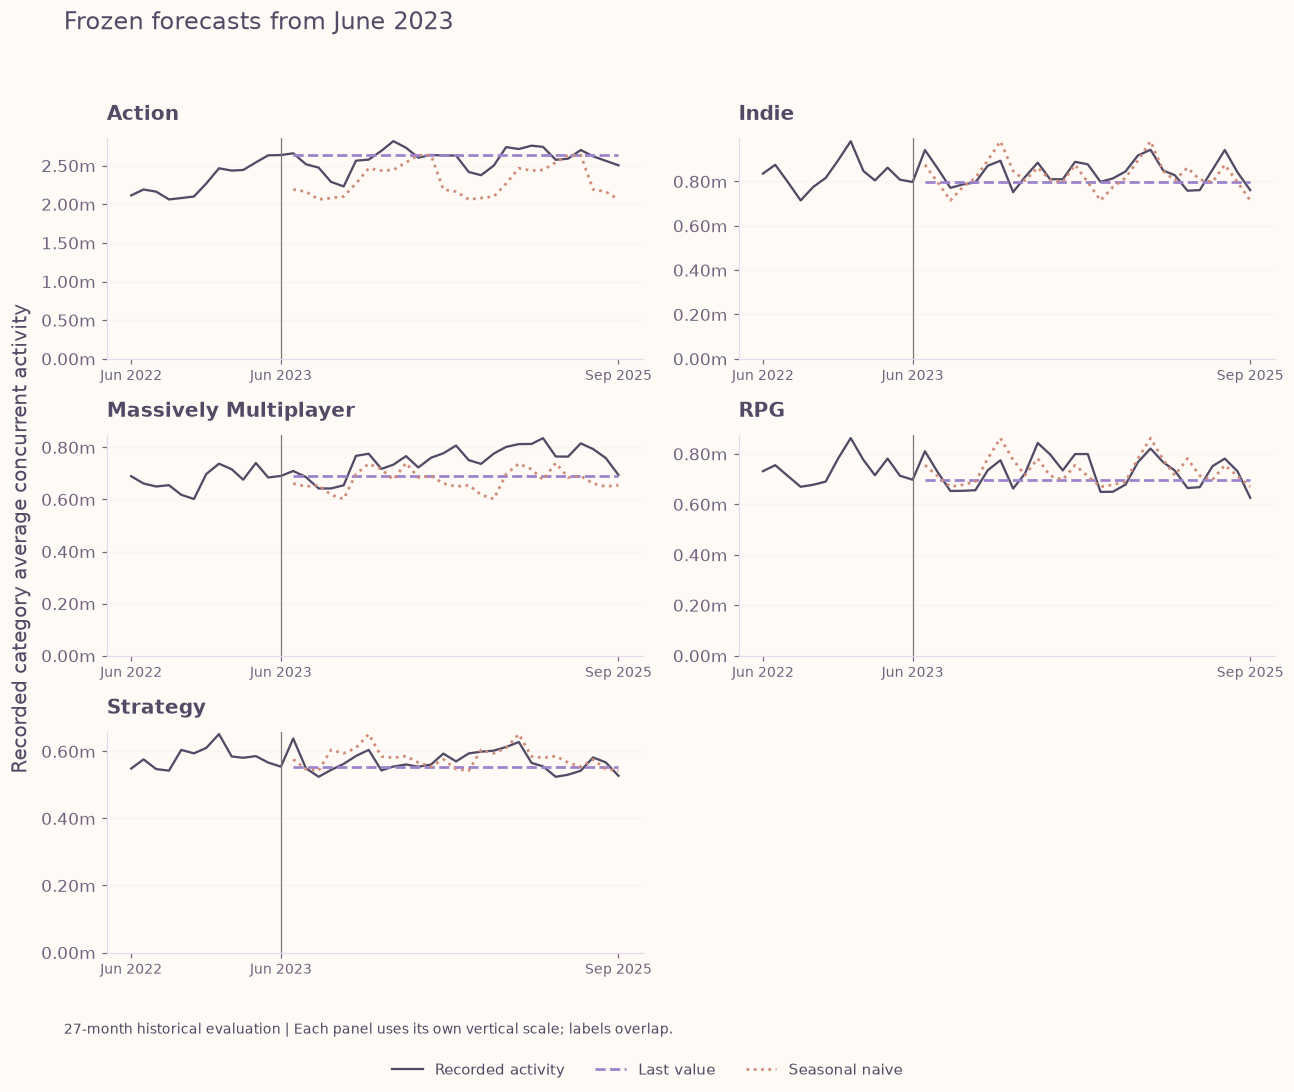

In [6]:
figure = plot_forecasts(monthly, predictions)
figure.savefig(figure_folder / "baseline_frozen_forecasts.png", dpi=150, bbox_inches="tight")
figure


The latest historical fold starts in June 2023 and runs through September 2025. The horizontal last-value forecast and repeating seasonal cycle show the assumptions directly, while deviations from recorded activity become the errors measured below.


## 4. Compare errors at the relevant leads

Forecast error is actual minus prediction, making positive mean error an indication of underprediction. MAE averages absolute errors in the activity units, while RMSE gives greater weight to large misses. WAPE divides total absolute error by total observed activity for the same category, model, and scoring window.

The long-lead comparison uses 48 predictions per category and method: 12 leads across four origins. Absolute errors remain tied to category size, so model comparisons are made within each label.


In [7]:
long_lead_scores = scores.loc[scores["window"].eq("Leads 16 to 27")]
present(long_lead_scores[[
    "category", "model", "scored_predictions", "mae", "rmse", "wape_pct"
]].round(2), 'Compare errors at the relevant leads')


Category,Model,Scored predictions,MAE,RMSE,WAPE
Action,Last value,48,"259,766.23","321,955.74",10.68%
Action,Seasonal naive,48,"332,754.30","385,214.57",13.68%
Indie,Last value,48,"66,931.97","84,656.98",8.09%
Indie,Seasonal naive,48,"101,775.52","130,380.73",12.30%
Massively Multiplayer,Last value,48,"64,311.70","73,158.29",9.01%
Massively Multiplayer,Seasonal naive,48,"75,472.38","88,985.73",10.58%
RPG,Last value,48,"57,019.74","67,054.79",7.81%
RPG,Seasonal naive,48,"83,441.83","114,870.47",11.44%
Strategy,Last value,48,"32,157.78","39,159.05",5.59%
Strategy,Seasonal naive,48,"45,987.08","67,488.53",7.99%


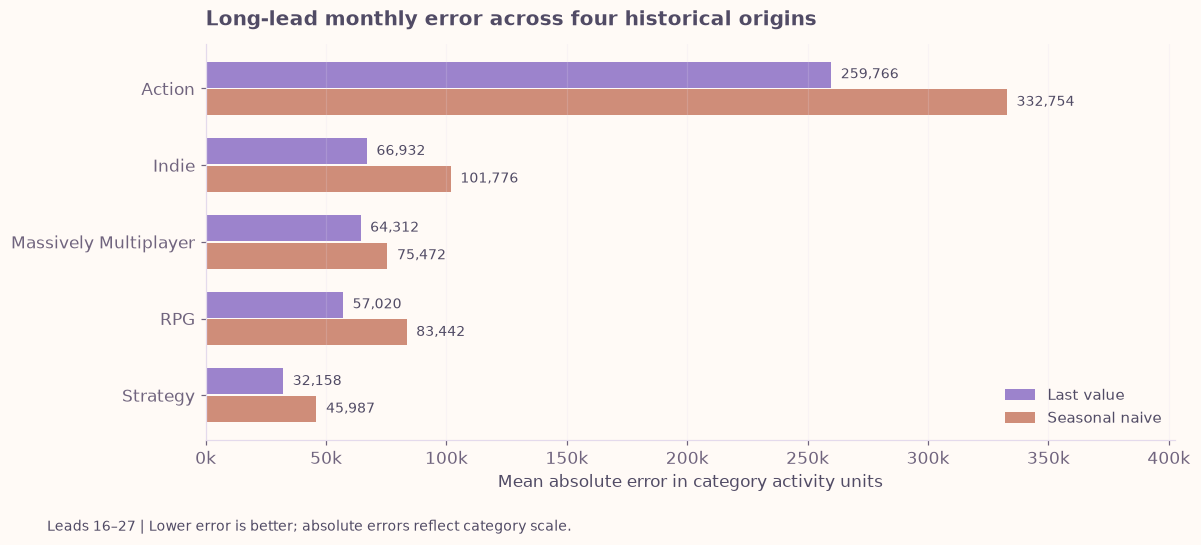

In [8]:
figure = plot_scores(scores)
figure.savefig(figure_folder / "baseline_long_lead_errors.png", dpi=150, bbox_inches="tight")
figure


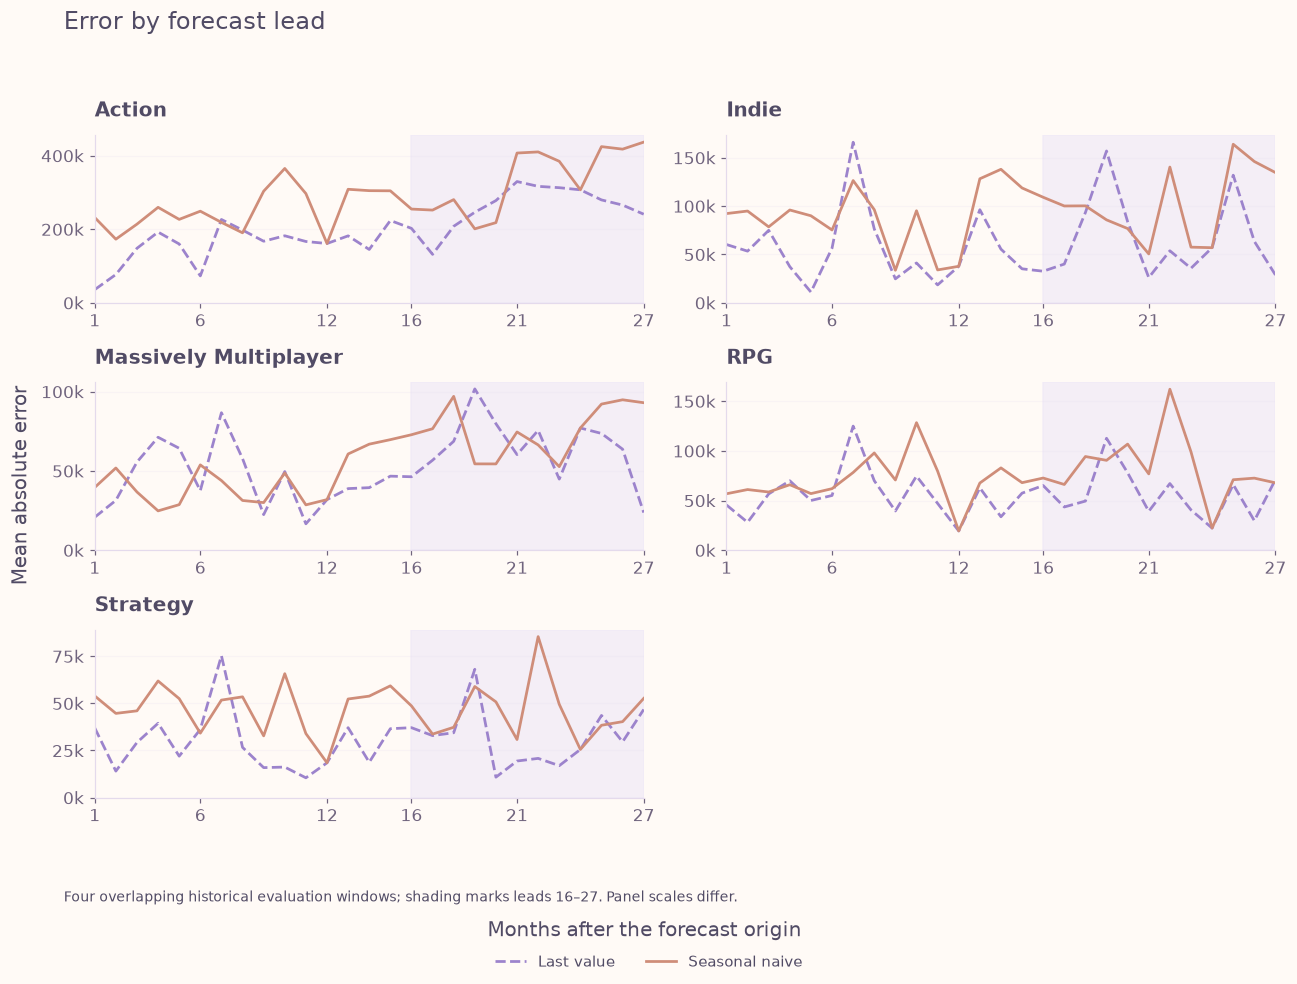

In [9]:
figure = plot_lead_errors(lead_scores)
figure.savefig(figure_folder / "baseline_errors_by_lead.png", dpi=150, bbox_inches="tight")
figure


The last-value method has lower pooled MAE for every label across leads 16–27, with Action at **259,766.23** compared with **332,754.30** for seasonal naive. This gives a simple benchmark for later models, while the four-fold average leaves variation between origins visible in the exported fold scores.


## 5. Separate monthly accuracy from the target average

The planned ranking uses average activity over a 12-month target period, so errors in that average are inspected separately from errors in individual months. Positive and negative monthly errors can cancel before averaging, which makes the two metrics answer different questions.


In [10]:
target_average_scores = target_means.groupby(
    ["category", "model"], as_index=False
).agg(
    mean_absolute_target_average_error=("absolute_mean_error", "mean"),
    origins=("origin", "nunique"),
)
present(target_average_scores.round(2), 'Separate monthly accuracy from the target average')


Category,Model,Mean absolute target-average error,Origins
Action,Last value,"229,773.56",4
Action,Seasonal naive,"245,371.77",4
Indie,Last value,"49,592.56",4
Indie,Seasonal naive,"69,948.34",4
Massively Multiplayer,Last value,"51,724.85",4
Massively Multiplayer,Seasonal naive,"66,923.44",4
RPG,Last value,"11,439.23",4
RPG,Seasonal naive,"27,925.32",4
Strategy,Last value,"21,599.97",4
Strategy,Seasonal naive,"16,800.63",4


For Strategy, seasonal naive has a lower mean absolute error in the target-period average (**16,800.64**) than last value (**21,599.97**), even though last value has lower monthly MAE. A final choice therefore needs the monthly trajectory and target-average task to be considered together.


In [11]:
later_origins = predictions.loc[predictions["origin"].ne(ORIGINS[0])]
sensitivity = score_forecasts(later_origins)
sensitivity.to_csv(ROOT / "reports/baseline_later_origin_sensitivity.csv", index=False)
present(sensitivity.loc[sensitivity["window"].eq("Leads 16 to 27")].pivot(
    index="category", columns="model", values="mae"
).round(2), 'Separate monthly accuracy from the target average')


model,Last value,Seasonal naive
category,,
Action,"294,372.06","327,111.28"
Indie,"67,351.53","67,482.06"
Massively Multiplayer,"70,324.85","86,566.89"
RPG,"53,888.53","49,697.77"
Strategy,"27,970.74","22,059.60"


Removing the earliest origin as a sensitivity check changes the long-lead MAE ordering for RPG and Strategy, where seasonal naive becomes lower. This comparison is reported alongside the full design rather than replacing it, showing how a limited set of origins can influence the result.

## Baseline findings

![Checkpoint 4 — findings, interpretation and the next decision](assets/pixel_theme/checkpoint_04.svg)

The two simple methods established reproducible, fixed-origin reference errors, with tests covering cutoff behaviour, long seasonal repetition, and error calculations. The later v1 model comparisons used these evaluation dates and metrics.

The benchmark predicts recorded activity under retrospective label and cohort assumptions, with the October 2019 missing-record cause and incomplete histories still unresolved. These v1 results did not resolve data freshness, origin coverage or uncertainty calibration.

Recorded evidence: [baseline scores](../reports/baseline_scores.csv).
